#Data Loading

In [ ]:
import pandas as pd

df=pd.read_csv("/content/mushrooms.csv")

print(df.head())
print(df.shape)

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

# Pre-Processing

In [ ]:
print("\nMissing Values:")
print(df.isna().sum())


Missing Values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [ ]:
categorical_col = df.select_dtypes(include=['object']).columns
print("categorical_columns : ",categorical_col)

categorical_columns :  Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')


In [ ]:
from sklearn.preprocessing import OrdinalEncoder
# Initialize the OrdinalEncoder
encoder = OrdinalEncoder()

# Apply the encoder on all columns of X
df_encoded = encoder.fit_transform(df)

df= pd.DataFrame(df_encoded, columns=df.columns)

df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1.0,5.0,2.0,4.0,1.0,6.0,1.0,0.0,1.0,4.0,...,2.0,7.0,7.0,0.0,2.0,1.0,4.0,2.0,3.0,5.0
1,0.0,5.0,2.0,9.0,1.0,0.0,1.0,0.0,0.0,4.0,...,2.0,7.0,7.0,0.0,2.0,1.0,4.0,3.0,2.0,1.0
2,0.0,0.0,2.0,8.0,1.0,3.0,1.0,0.0,0.0,5.0,...,2.0,7.0,7.0,0.0,2.0,1.0,4.0,3.0,2.0,3.0
3,1.0,5.0,3.0,8.0,1.0,6.0,1.0,0.0,1.0,5.0,...,2.0,7.0,7.0,0.0,2.0,1.0,4.0,2.0,3.0,5.0
4,0.0,5.0,2.0,3.0,0.0,5.0,1.0,1.0,0.0,4.0,...,2.0,7.0,7.0,0.0,2.0,1.0,0.0,3.0,0.0,1.0


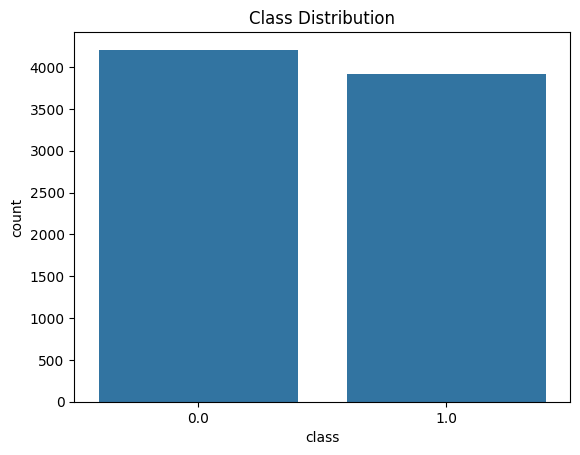

class
0.0    4208
1.0    3916
Name: count, dtype: int64


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
# Check the distribution of the target variable ('class')

sns.countplot(x='class', data=df)
plt.title('Class Distribution')
plt.show()
conts=df['class'].value_counts()
print(conts)

EDA

First 5 rows of the dataset:
   class  cap-shape  cap-surface  cap-color  bruises  odor  gill-attachment  \
0    1.0        5.0          2.0        4.0      1.0   6.0              1.0   
1    0.0        5.0          2.0        9.0      1.0   0.0              1.0   
2    0.0        0.0          2.0        8.0      1.0   3.0              1.0   
3    1.0        5.0          3.0        8.0      1.0   6.0              1.0   
4    0.0        5.0          2.0        3.0      0.0   5.0              1.0   

   gill-spacing  gill-size  gill-color  ...  stalk-surface-below-ring  \
0           0.0        1.0         4.0  ...                       2.0   
1           0.0        0.0         4.0  ...                       2.0   
2           0.0        0.0         5.0  ...                       2.0   
3           0.0        1.0         5.0  ...                       2.0   
4           1.0        0.0         4.0  ...                       2.0   

   stalk-color-above-ring  stalk-color-below-ring  veil-t

<Figure size 1500x1000 with 0 Axes>

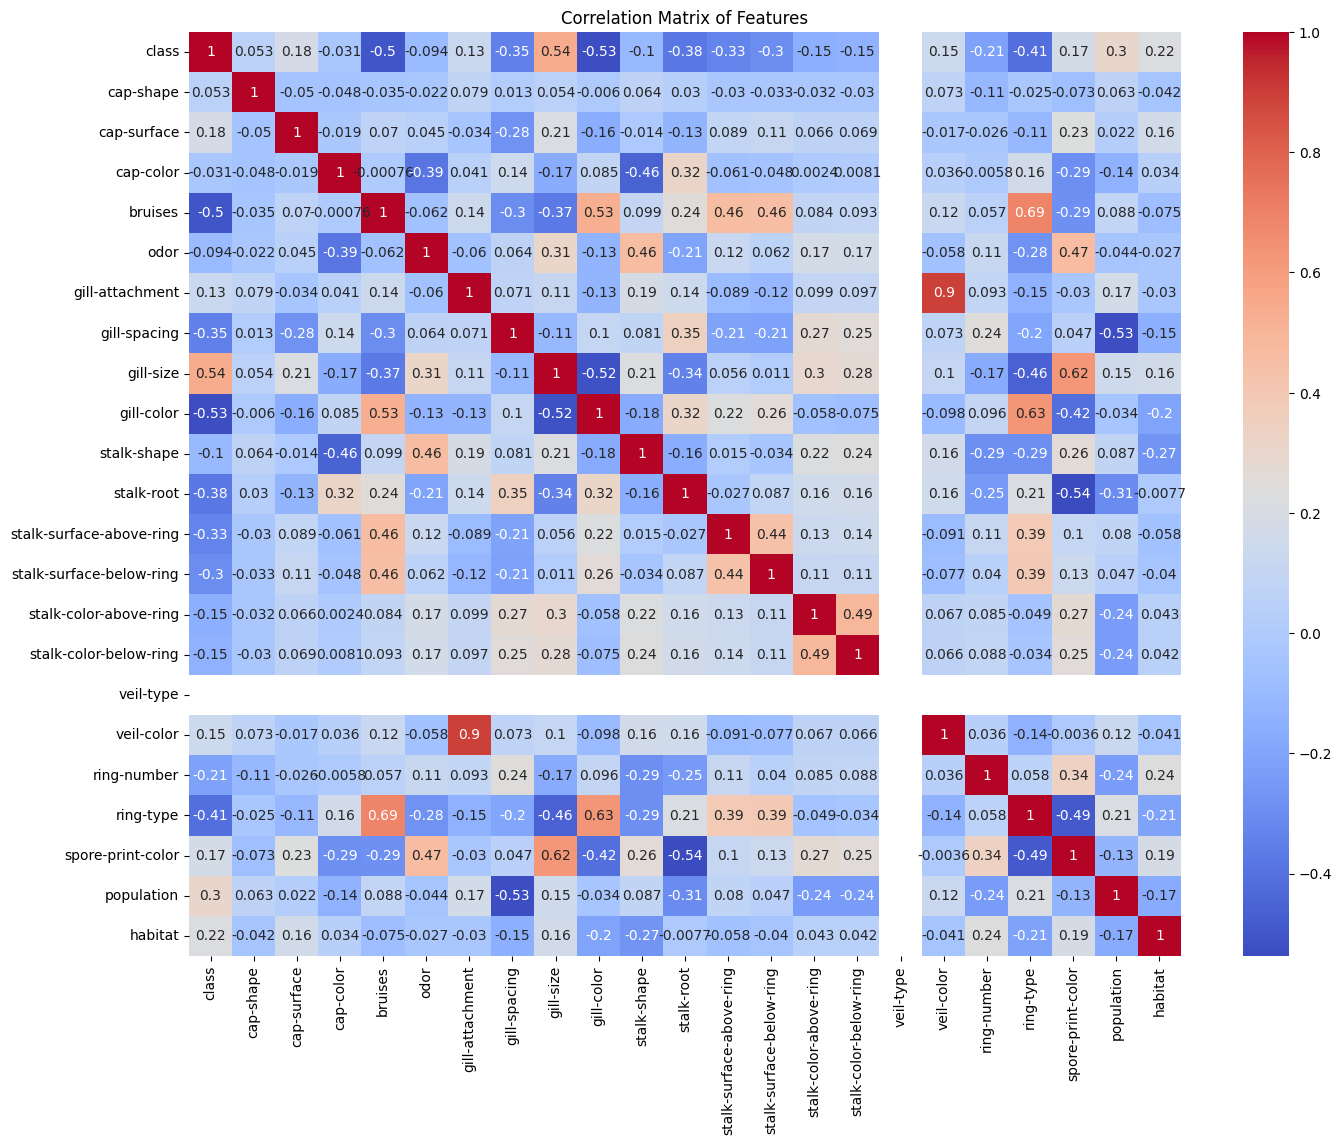

Percentage of outliers: 4.19%


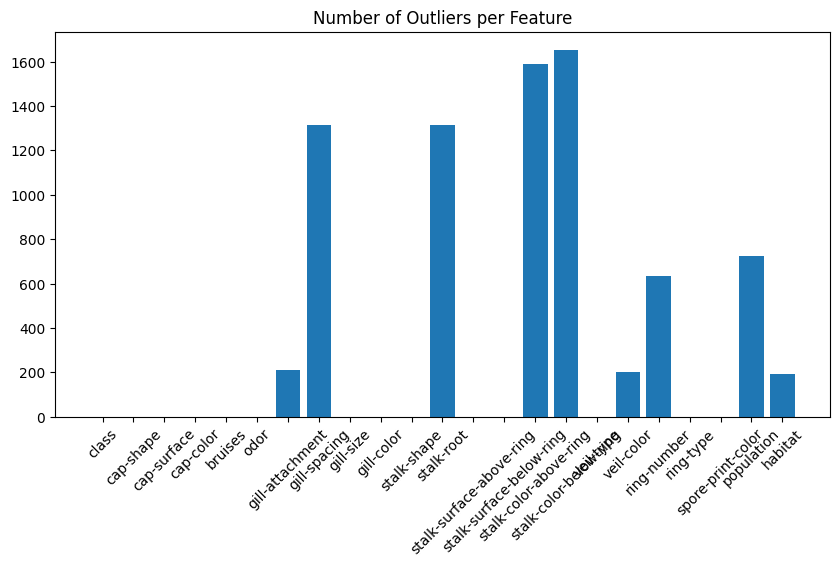

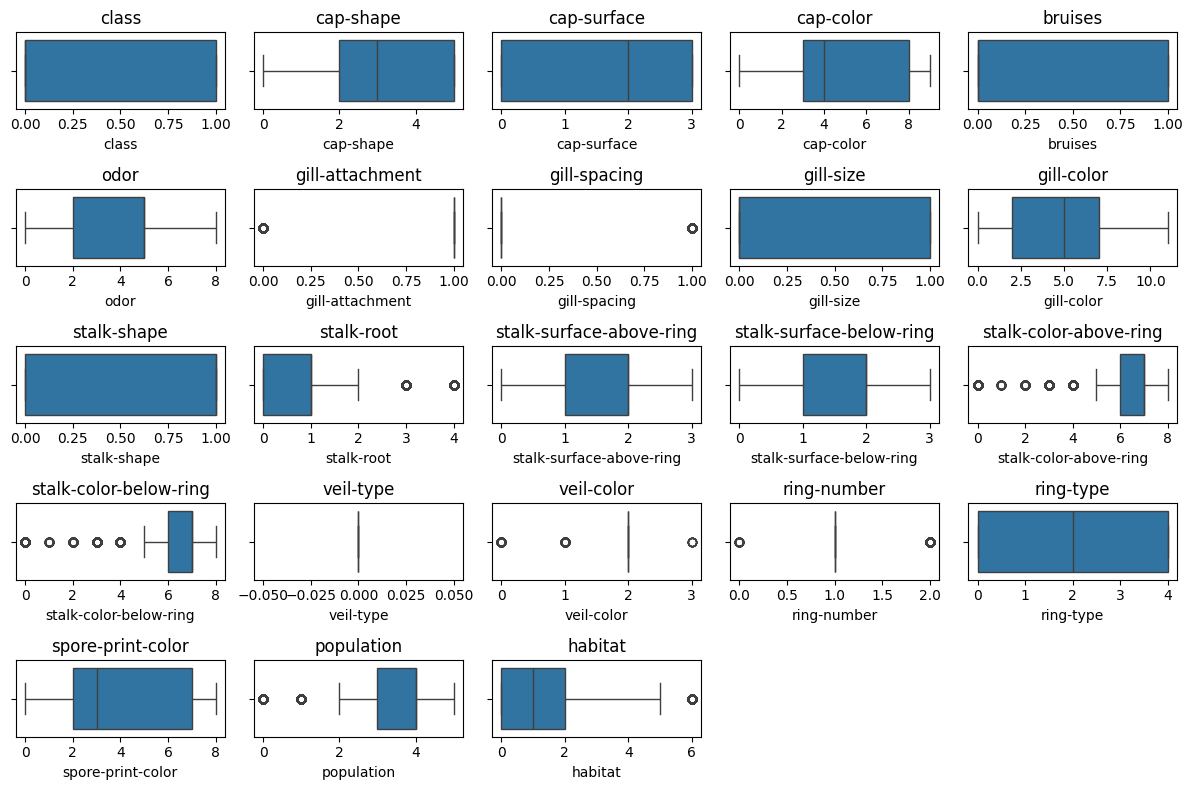

In [ ]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Print dataset summary
print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDescribing data:")
print(df.describe())

# Display descriptive statistics
print("Descriptive statistics of the dataset:")
print(df.describe())

duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

# Select numeric columns
numeric_col = df.select_dtypes(include=['number']).columns

# Select categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

# Plotting distribution of categorical variables
plt.figure(figsize=(15, 10))
for i, column in enumerate(categorical_columns, 1):
    plt.subplot(5, 5, i)  # Adjusted subplot grid for more columns
    sns.histplot(df[column], kde=True)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

# Correlation matrix
corr_matrix = df.corr()

# Plot heatmap of correlation matrix
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Features')
plt.show()

# Identifying outliers using the IQR method
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))

# Percentage of outliers
outliers = outlier_mask.sum().sum() / np.product(df.shape) * 100
print(f"Percentage of outliers: {outliers:.2f}%")

# Plot histogram of outliers
plt.figure(figsize=(10, 5))
outlier_counts = outlier_mask.sum(axis=0)
plt.bar(df.columns, outlier_counts)
plt.xticks(rotation=45)
plt.title('Number of Outliers per Feature')
plt.show()

# Visualizing outliers with box plots for numerical columns
plt.figure(figsize=(12, 8))
for i, column in enumerate(df.columns, 1):
    plt.subplot(5, 5, i)
    sns.boxplot(x=df[column])
    plt.title(column)
plt.tight_layout()
plt.show()

Splitting Data

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# get the locations
X = df.iloc[:, 1:]
y = df.iloc[:, 0]

# split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) # check for random_state=0 also

print(f"\nTraining feature:\n{X_train.head()}")
print(f"\nTraining target:\n{y_train.head()}")
print(f"\nTest features:\n{X_test.head()}")
print(f"\nTest target:\n{y_test.head()}")

print(f"\nTraining feature:\n{X_train.shape}")
print(f"\nTraining target:\n{y_train.shape}")
print(f"\nTest features:\n{X_test.shape}")
print(f"\nTest target:\n{y_test.shape}")


Training feature:
      cap-shape  cap-surface  cap-color  bruises  odor  gill-attachment  \
5921        5.0          2.0        0.0      1.0   2.0              1.0   
1073        5.0          0.0        3.0      1.0   5.0              1.0   
3710        5.0          0.0        3.0      0.0   2.0              1.0   
144         5.0          3.0        9.0      1.0   0.0              1.0   
5469        5.0          3.0        4.0      0.0   8.0              1.0   

      gill-spacing  gill-size  gill-color  stalk-shape  ...  \
5921           0.0        0.0         3.0          1.0  ...   
1073           0.0        0.0         7.0          1.0  ...   
3710           0.0        0.0         7.0          0.0  ...   
144            0.0        0.0         4.0          0.0  ...   
5469           0.0        1.0         0.0          1.0  ...   

      stalk-surface-below-ring  stalk-color-above-ring  \
5921                       0.0                     7.0   
1073                       2.0     

Implementing PCA

In [ ]:
#IMPLIMENTING PCA with outliers
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=10)  # Adjust the number of components based on variance explained
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Print explained variance ratio
print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.18477636 0.12424535 0.11394205 0.10329988 0.08132777 0.06595028
 0.04655041 0.0456523  0.03625504 0.03491952]


Implimenting LDA

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply LDA for dimensionality reduction
lda = LDA(n_components=1)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

# Perform LDA on the entire dataset for predictions and evaluation
lda_full = LDA()
lda_full.fit(X_train, y_train)

# Predictions and evaluation
y_pred = lda_full.predict(X_test)
print("Accuracy with outliers:", accuracy_score(y_test, y_pred))

# Confusion matrix
print("Confusion Matrix with outliers:\n", confusion_matrix(y_test, y_pred))

Accuracy with outliers: 0.9479081214109926
Confusion Matrix with outliers:
 [[1205   52]
 [  75 1106]]


Removing Outliers

In [ ]:
# Remove outliers
df_clean = df_encoded[~outlier_mask.any(axis=1)]
# Convert df_clean to DataFrame with original columns if df_encoded was a DataFrame initially

df_clean = pd.DataFrame(df_clean, columns=[f'col_{i}' for i in range(23)])
X_clean = df_clean.iloc[:, 1:]
y_clean = df_clean.iloc[:, 0]

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(X_clean, y_clean, test_size=0.3, random_state=42)

PCA without Outliers

In [ ]:
#pca without outliers
scaler = StandardScaler()
X_train_scaled_clean = scaler.fit_transform(X_train_clean)
X_test_scaled_clean = scaler.transform(X_test_clean)

pca_clean = PCA(n_components=10)  # Adjust the number of components based on variance explained
X_train_pca_clean = pca_clean.fit_transform(X_train_scaled_clean)
X_test_pca_clean = pca_clean.transform(X_test_scaled_clean)

# Print explained variance ratio
print("Explained variance ratio:", pca_clean.explained_variance_ratio_)

Explained variance ratio: [0.38376891 0.14203316 0.07947504 0.06358507 0.06069263 0.04706917
 0.04619959 0.04336141 0.03954707 0.03164845]


LDA without Outliers

In [ ]:
# Perform LDA on clean data without outliers
lda_clean = LDA()
lda_clean.fit(X_train_scaled_clean, y_train_clean)

# Predictions and evaluation
y_pred_clean = lda_clean.predict(X_test_scaled_clean)
print("Accuracy without outliers:", accuracy_score(y_test_clean, y_pred_clean))

# Confusion matrix
print("Confusion Matrix without outliers:\n", confusion_matrix(y_test_clean, y_pred_clean))

Accuracy without outliers: 0.9907407407407407
Confusion Matrix without outliers:
 [[428   0]
 [ 10 642]]


# Classification on Original Dataset.

Cross validation for optimal K selection

The best k value is 1 with accuracy: 99.96%


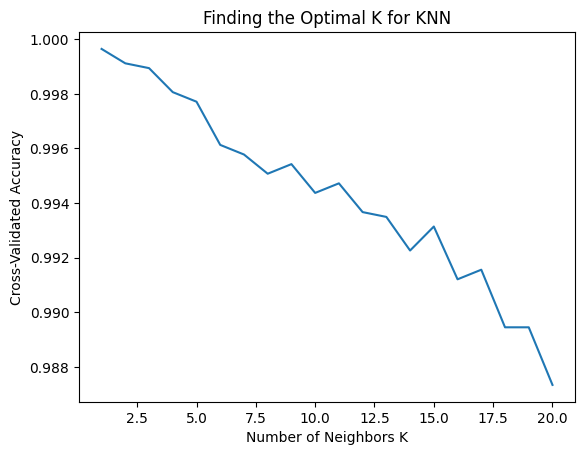

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

# Define the range of k values to test
k_values = range(1, 21)
cv_scores = []  # List to store cross-validation scores

# Loop over k values
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    # Perform 10-fold cross-validation
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    # Append the average score for this k
    cv_scores.append(scores.mean())

# Find the best k (the one with the highest average accuracy)
best_k = k_values[cv_scores.index(max(cv_scores))]
print(f"The best k value is {best_k} with accuracy: {max(cv_scores) * 100:.2f}%")

# Plotting the results
plt.plot(k_values, cv_scores)
plt.xlabel('Number of Neighbors K')
plt.ylabel('Cross-Validated Accuracy')
plt.title('Finding the Optimal K for KNN')
plt.show()

KNN

KNN Model Accuracy on Original Data: 0.9987694831829368
KNN Classification Report on Original Data:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1257
         1.0       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



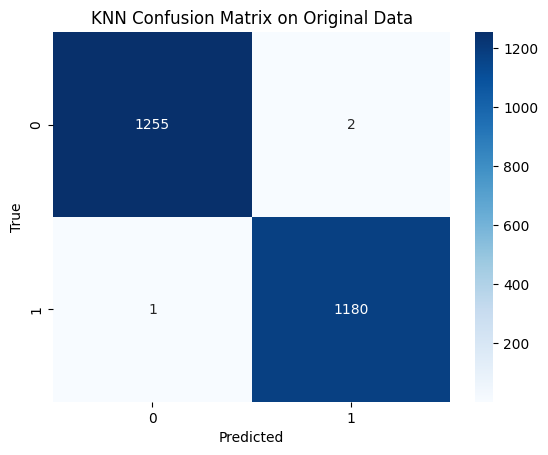

In [ ]:
#KNN without pca with outliers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
# Initialize the KNN model
knn = KNeighborsClassifier(n_neighbors=1)  # You can tune n_neighbors for better results

# Train the KNN model on the original data
knn.fit(X_train, y_train)

# Predict on test set
y_pred = knn.predict(X_test)

# Calculate accuracy and print classification report
accuracy = accuracy_score(y_test, y_pred)
print("KNN Model Accuracy on Original Data:", accuracy)
print("KNN Classification Report on Original Data:\n", classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("KNN Confusion Matrix on Original Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

KNN Model Accuracy on Original Data: 0.9954881050041017
KNN Classification Report on Original Data:
               precision    recall  f1-score   support

         0.0       1.00      0.99      1.00      1257
         1.0       0.99      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



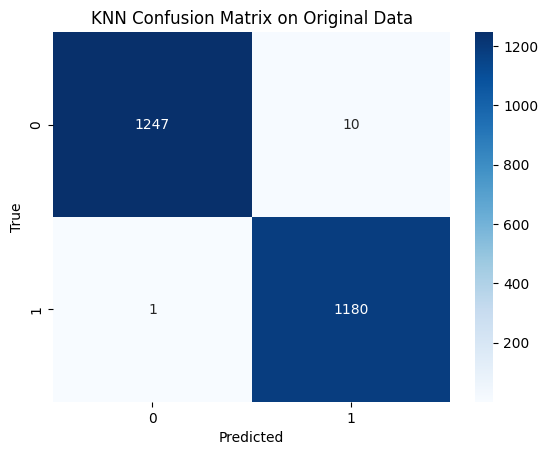

In [ ]:
#KNN without pca with outliers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
# Initialize the KNN model
knn = KNeighborsClassifier(n_neighbors=5)  # You can tune n_neighbors for better results

# Train the KNN model on the original data
knn.fit(X_train, y_train)

# Predict on test set
y_pred = knn.predict(X_test)

# Calculate accuracy and print classification report
accuracy = accuracy_score(y_test, y_pred)
print("KNN Model Accuracy on Original Data:", accuracy)
print("KNN Classification Report on Original Data:\n", classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("KNN Confusion Matrix on Original Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

KNN Model Accuracy on Original Data: 0.992616899097621
KNN Classification Report on Original Data:
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      1257
         1.0       0.99      0.99      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438



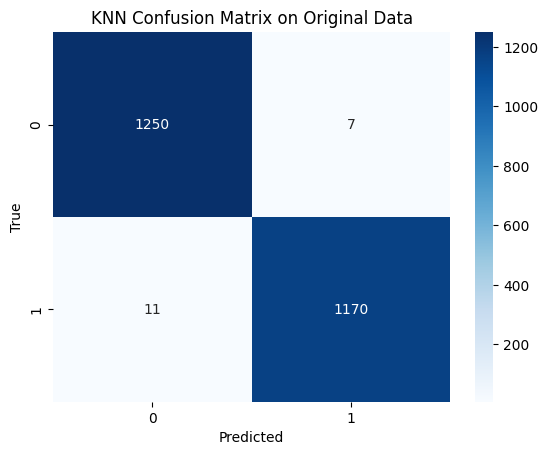

In [ ]:
#KNN without pca with outliers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
# Initialize the KNN model
knn = KNeighborsClassifier(n_neighbors=10)  # You can tune n_neighbors for better results

# Train the KNN model on the original data
knn.fit(X_train, y_train)

# Predict on test set
y_pred = knn.predict(X_test)

# Calculate accuracy and print classification report
accuracy = accuracy_score(y_test, y_pred)
print("KNN Model Accuracy on Original Data:", accuracy)
print("KNN Classification Report on Original Data:\n", classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("KNN Confusion Matrix on Original Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Logistic Regression

Accuracy with outliers: 0.9491
KNN Classification Report on Original Data:
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      1257
         1.0       0.99      0.99      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438



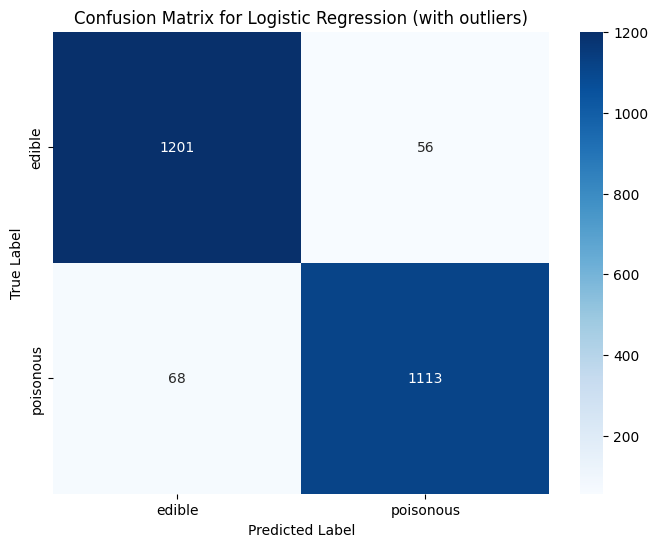

In [ ]:
#logisticregression with outliers
from sklearn.linear_model import LogisticRegression
log_reg_with_outliers = LogisticRegression(max_iter=1000, random_state=42)
log_reg_with_outliers.fit(X_train, y_train)

# Predictions and evaluation
y_pred_with_outliers = log_reg_with_outliers.predict(X_test)
accuracy_with_outliers = accuracy_score(y_test, y_pred_with_outliers)
print(f"Accuracy with outliers: {accuracy_with_outliers:.4f}")
print("KNN Classification Report on Original Data:\n", classification_report(y_test, y_pred))
# Plot confusion matrix for logistic regression with outliers
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_with_outliers), annot=True, fmt='d', cmap='Blues',
            xticklabels=['edible', 'poisonous'], yticklabels=['edible', 'poisonous'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression (with outliers)')
plt.show()

SVM

Accuracy without PCA and with outliers: 1.0
KNN Classification Report on Original Data:
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      1257
         1.0       0.99      0.99      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438



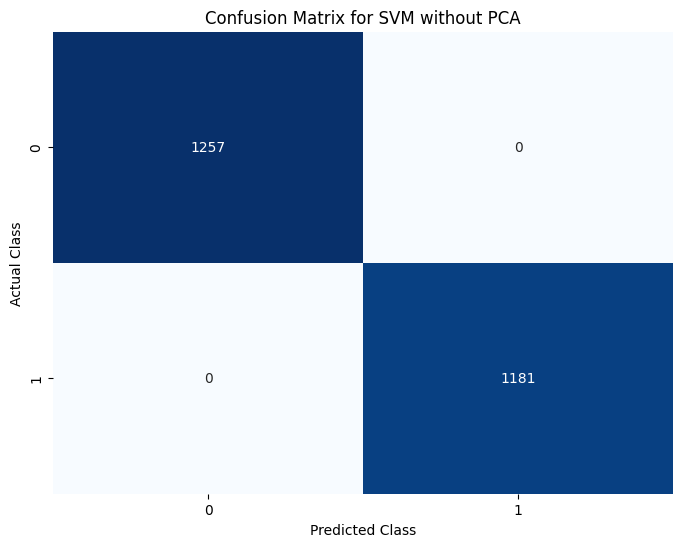

In [ ]:
#SVM without PCA with outliers
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

model_no_pca = SVC()
model_no_pca.fit(X_train_scaled, y_train)
y_pred_no_pca = model_no_pca.predict(X_test_scaled)

accuracy_no_pca = accuracy_score(y_test, y_pred_no_pca)
print(f"Accuracy without PCA and with outliers: {accuracy_no_pca}")
print("KNN Classification Report on Original Data:\n", classification_report(y_test, y_pred))
# Calculate confusion matrix for the model without PCA
conf_matrix_no_pca = confusion_matrix(y_test, y_pred_no_pca)

# Plot confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_no_pca, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix for SVM without PCA')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

Decision Tree using gini index

Training-set accuracy score: 95.9022
Test-set accuracy score: 95.7752


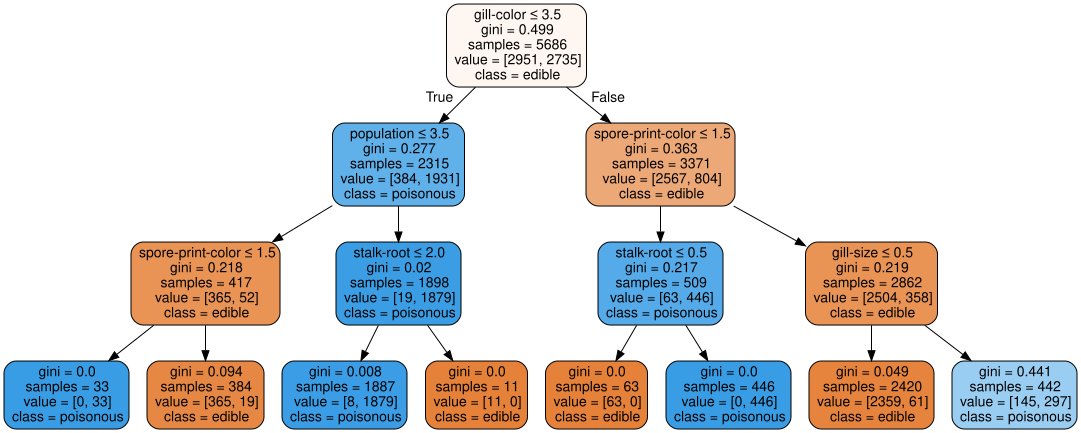

In [ ]:
#with gini
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import graphviz
# instantiate the DecisionTreeClassifier model with criterion gini index
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=0)

# fit the model
clf_gini.fit(X_train, y_train)

y_pred_train_gini = clf_gini.predict(X_train)
y_pred_gini = clf_gini.predict(X_test)


print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train_gini)*100))
print('Test-set accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_gini)*100))
features = X.columns.tolist()
classes = ['edible', 'poisonous']
dot_data = tree.export_graphviz(clf_gini, out_file=None,
                              feature_names=X.columns,
                              class_names=classes,
                              filled=True, rounded=True,
                              special_characters=True)

graph = graphviz.Source(dot_data)

graph


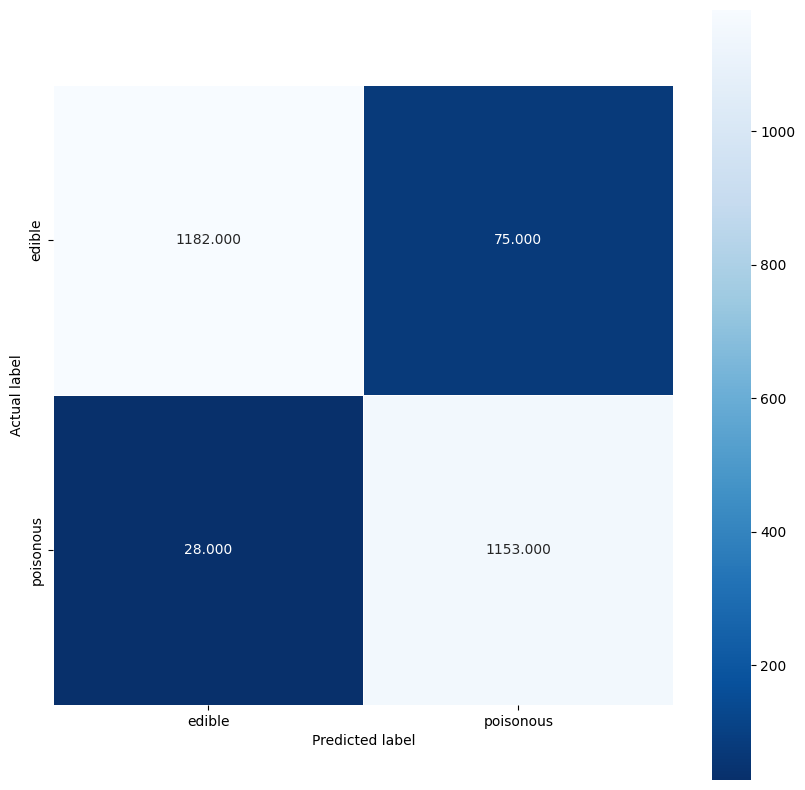

In [ ]:
# Print the Confusion Matrix and slice it into four pieces
cm = confusion_matrix(y_test, y_pred_gini)

cm_df = pd.DataFrame(cm, index=classes, columns=classes)

# plot with proper column names
plt.figure(figsize=(10,10))
sns.heatmap(cm_df, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r')
plt.ylabel('Actual label');
plt.xlabel('Predicted label');

Decision Tree using entropy

Training-set accuracy score: 95.8846
Test-set accuracy score: 95.3240


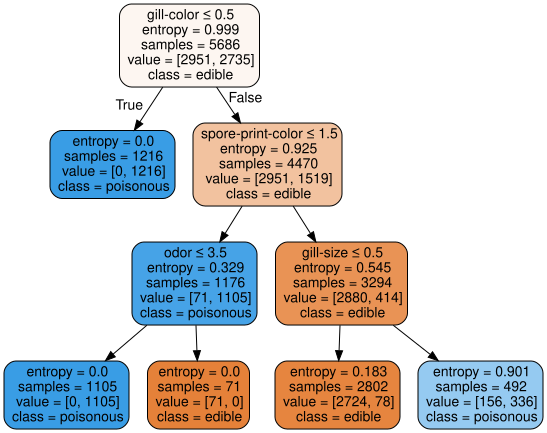

In [ ]:
#Using entropy
# instantiate the DecisionTreeClassifier model with criterion entropy
clf_en = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=0)

# fit the model
clf_en.fit(X_train, y_train)

y_pred_train_en = clf_en.predict(X_train)
y_pred_en = clf_en.predict(X_test)

from sklearn.metrics import accuracy_score

print('Training-set accuracy score: {0:0.4f}'. format(accuracy_score(y_train, y_pred_train_en)*100))
print('Test-set accuracy score: {0:0.4f}'. format(accuracy_score(y_test, y_pred_en)*100))

dot_data = tree.export_graphviz(clf_en, out_file=None,
                              feature_names=X_train.columns,
                              class_names=classes,
                              filled=True, rounded=True,
                              special_characters=True)

graph = graphviz.Source(dot_data)

graph


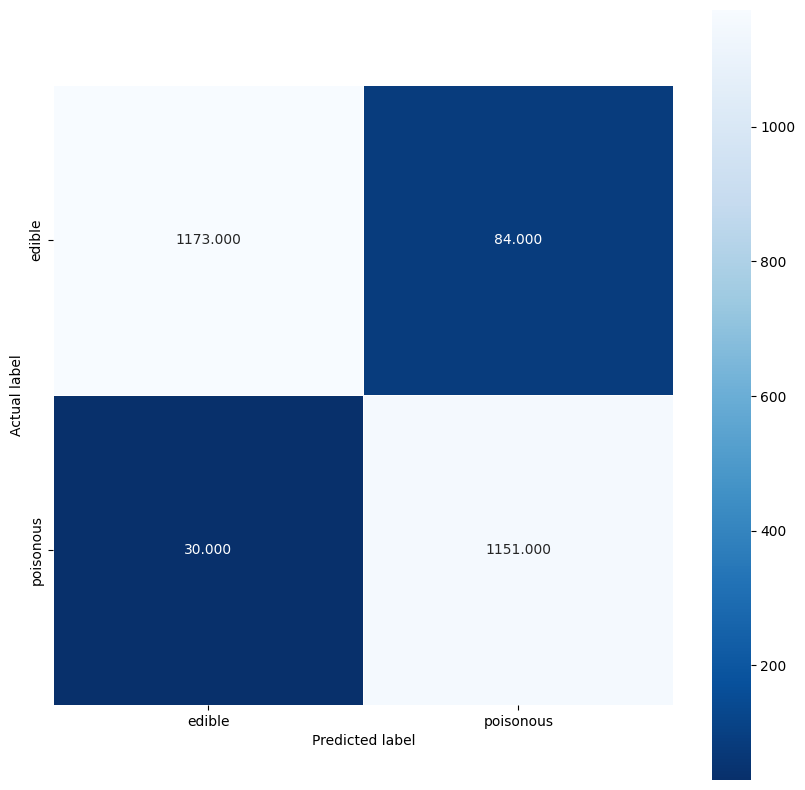

In [ ]:
# Print the Confusion Matrix and slice it into four pieces
cm = confusion_matrix(y_test, y_pred_en)

cm_df = pd.DataFrame(cm, index=classes, columns=classes)
# plot with proper column names
plt.figure(figsize=(10,10))
sns.heatmap(cm_df, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r')
plt.ylabel('Actual label');
plt.xlabel('Predicted label');

# Classification of data using PCA

## With PCA and With Outliers

KNN

KNN Model Accuracy on PCA Data: 0.9983593109105825
KNN Classification Report on PCA Data:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1257
         1.0       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



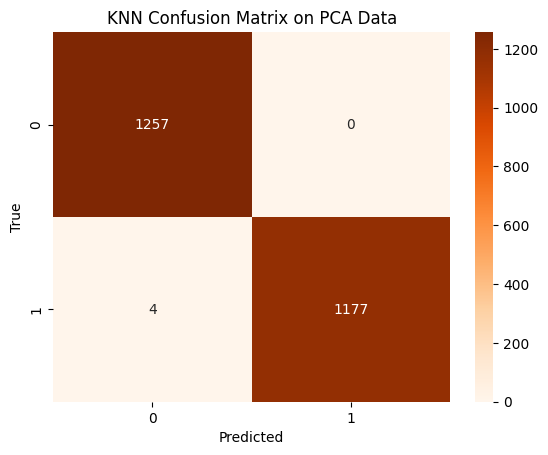

In [ ]:
# KNN WITH PCA
knn_pca = KNeighborsClassifier(n_neighbors=1)
knn_pca.fit(X_train_pca, y_train)
# Predict on PCA-transformed test set
y_knn_pred_pca = knn_pca.predict(X_test_pca)

# Calculate accuracy and print classification report
accuracy_knn_pca = accuracy_score(y_test, y_knn_pred_pca)
print("KNN Model Accuracy on PCA Data:", accuracy_knn_pca)
print("KNN Classification Report on PCA Data:\n", classification_report(y_test, y_knn_pred_pca))

# Confusion matrix
cm_pca = confusion_matrix(y_test, y_knn_pred_pca)
sns.heatmap(cm_pca, annot=True, fmt="d", cmap="Oranges")
plt.title("KNN Confusion Matrix on PCA Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Logistic Regression

Accuracy with outliers (PCA): 0.9024


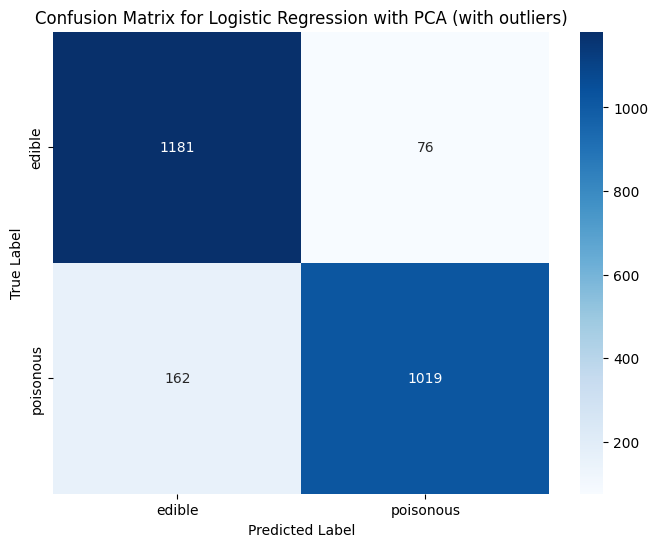

In [ ]:
#L.R WITH PCA
lr_train_pca = pca.fit_transform(X_train)
lr_test_pca = pca.transform(X_test)

# Train logistic regression
lr_with_outliers = LogisticRegression(max_iter=1000, random_state=42)
lr_with_outliers.fit(X_train_pca, y_train)

# Predictions and evaluation
y_lr_pred_with_outliers = lr_with_outliers.predict(X_test_pca)
accuracy_lr_with_outliers = accuracy_score(y_test, y_lr_pred_with_outliers)
print(f"Accuracy with outliers (PCA): {accuracy_lr_with_outliers:.4f}")

# Plot confusion matrix for logistic regression with outliers
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_lr_pred_with_outliers), annot=True, fmt='d', cmap='Blues',
            xticklabels=['edible', 'poisonous'], yticklabels=['edible', 'poisonous'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression with PCA (with outliers)')
plt.show()

SVM

Accuracy with PCA and outliers: 0.9983593109105825


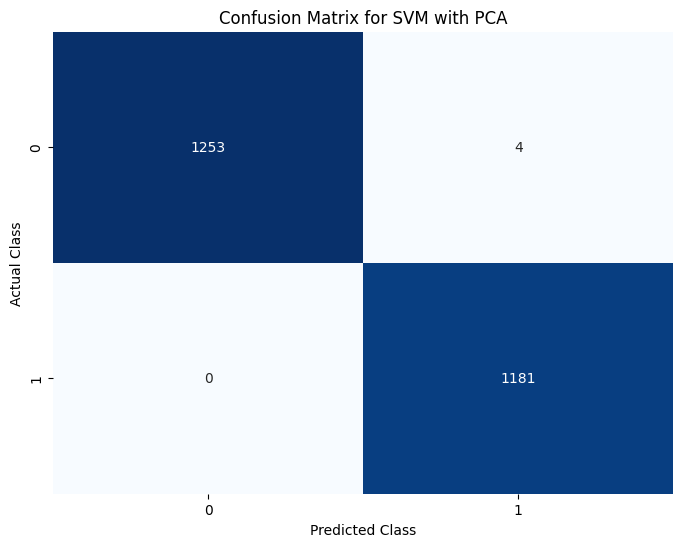

In [ ]:
#SVM with PCA
model_svm_pca = SVC()
model_svm_pca.fit(X_train_pca, y_train)
y_svm_pred_pca = model_svm_pca.predict(X_test_pca)

accuracy_svm_pca = accuracy_score(y_test, y_svm_pred_pca)
print(f"Accuracy with PCA and outliers: {accuracy_svm_pca}")

# Calculate confusion matrix
conf_svm_matrix = confusion_matrix(y_test, y_svm_pred_pca)

# Plot confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_svm_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix for SVM with PCA')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()


Decision Tree

[[1257    0]
 [ 303  878]]
              precision    recall  f1-score   support

         0.0       0.81      1.00      0.89      1257
         1.0       1.00      0.74      0.85      1181

    accuracy                           0.88      2438
   macro avg       0.90      0.87      0.87      2438
weighted avg       0.90      0.88      0.87      2438

Accuracy: 0.8757


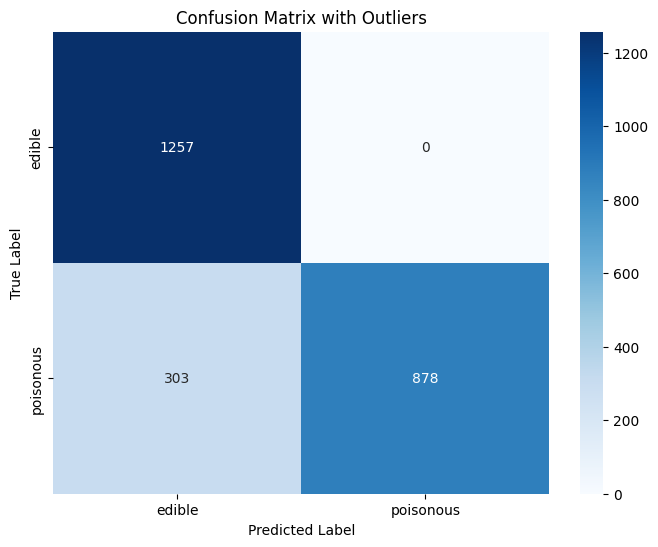

In [ ]:
#D.T with PCA
X_dt_train_pca = pca.fit_transform(X_train_scaled)
X_dt_test_pca = pca.transform(X_test_scaled)

# Train Decision Tree model
model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=0)
model.fit(X_dt_train_pca, y_train)

# Predictions
y_dt_pred = model.predict(X_test_pca)

# Evaluate model
print(confusion_matrix(y_test, y_dt_pred))
print(classification_report(y_test, y_dt_pred))

# Calculate accuracy
accuracy = accuracy_score(y_test, y_dt_pred)
print(f'Accuracy: {accuracy:.4f}')

# Plot confusion matrix
conf_matrix = confusion_matrix(y_test, y_dt_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['edible', 'poisonous'], yticklabels=['edible', 'poisonous'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix with Outliers')
plt.show()

## with PCA without Outliers

KNN

KNN Model Accuracy on PCA Data: 1.0
KNN Classification Report on PCA Data:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00       428
         1.0       1.00      1.00      1.00       652

    accuracy                           1.00      1080
   macro avg       1.00      1.00      1.00      1080
weighted avg       1.00      1.00      1.00      1080



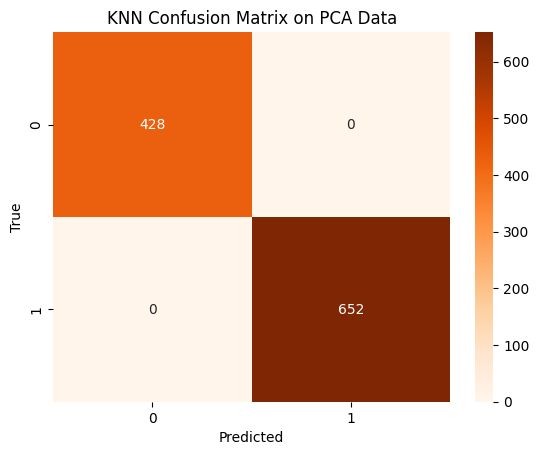

In [ ]:
#KNN with PCA without outliers
knn_pca_clean = KNeighborsClassifier(n_neighbors=1)
knn_pca_clean.fit(X_train_pca_clean, y_train_clean)

# Predict on PCA-transformed test set
y_knn_pred_pca_clean = knn_pca_clean.predict(X_test_pca_clean)

# Calculate accuracy and print classification report
accuracy_knn_pca_clean = accuracy_score(y_test_clean, y_knn_pred_pca_clean)
print("KNN Model Accuracy on PCA Data:", accuracy_knn_pca_clean)
print("KNN Classification Report on PCA Data:\n", classification_report(y_test_clean, y_knn_pred_pca_clean))

# Confusion matrix
cm_pca = confusion_matrix(y_test_clean, y_knn_pred_pca_clean)
sns.heatmap(cm_pca, annot=True, fmt="d", cmap="Oranges")
plt.title("KNN Confusion Matrix on PCA Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Logistic Regression

Accuracy with outliers (PCA): 0.9907


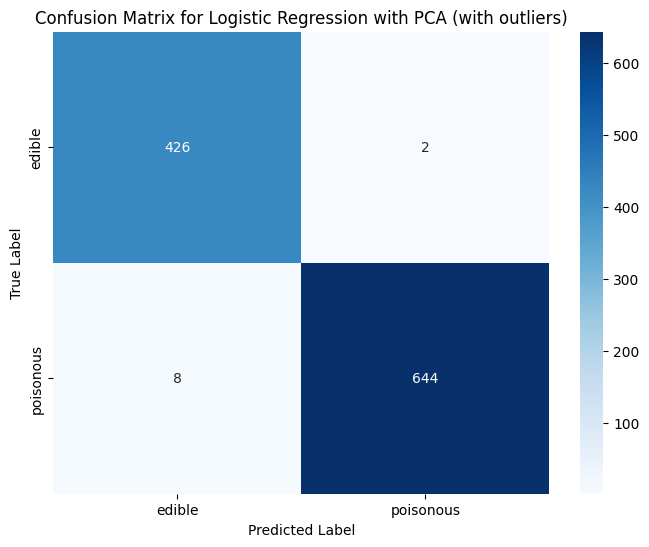

In [ ]:
#L.R with pca without outliers
lr_train_pca_clean = pca.fit_transform(X_train_clean)
lr_test_pca_clean = pca.transform(X_test_clean)

# Train logistic regression
lr_clean = LogisticRegression(max_iter=1000, random_state=42)
lr_clean.fit(X_train_pca_clean, y_train_clean)

# Predictions and evaluation
y_lr_pred_clean = lr_clean.predict(X_test_pca_clean)
accuracy_lr_clean = accuracy_score(y_test_clean, y_lr_pred_clean)
print(f"Accuracy with outliers (PCA): {accuracy_lr_clean:.4f}")

# Plot confusion matrix for logistic regression with outliers
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_clean, y_lr_pred_clean), annot=True, fmt='d', cmap='Blues',
            xticklabels=['edible', 'poisonous'], yticklabels=['edible', 'poisonous'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression with PCA (with outliers)')
plt.show()

SVM

Accuracy with PCA and outliers: 1.0


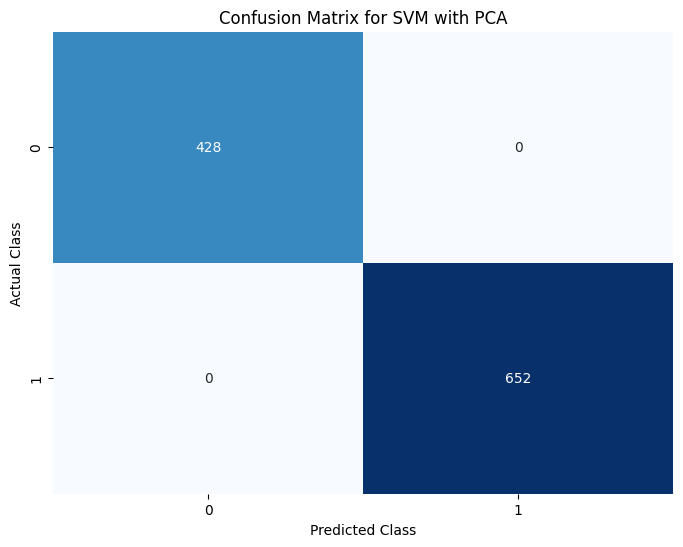

In [ ]:
#SVM with PCA without outliers
svm_pca_clean = SVC()
svm_pca_clean.fit(X_train_pca_clean, y_train_clean)
y_svm_pred_pca_clean = svm_pca_clean.predict(X_test_pca_clean)

accuracy_svm_pca_clean = accuracy_score(y_test_clean, y_svm_pred_pca_clean)
print(f"Accuracy with PCA and outliers: {accuracy_svm_pca_clean}")

# Calculate confusion matrix
conf_svm_matrix = confusion_matrix(y_test_clean, y_svm_pred_pca_clean)

# Plot confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_svm_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix for SVM with PCA')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

Decision Tree

[[428   0]
 [ 12 640]]
              precision    recall  f1-score   support

         0.0       0.97      1.00      0.99       428
         1.0       1.00      0.98      0.99       652

    accuracy                           0.99      1080
   macro avg       0.99      0.99      0.99      1080
weighted avg       0.99      0.99      0.99      1080

Accuracy: 0.9889


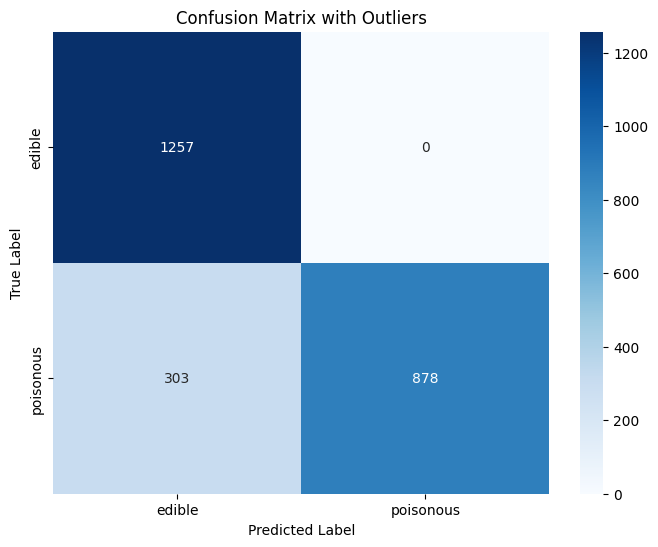

In [ ]:
#D.T with PCA without outliers
X_dt_train_pca_clean = pca.fit_transform(X_train_scaled_clean)
X_dt_test_pca_clean = pca.transform(X_test_scaled_clean)

# Train Decision Tree model
model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=0)
model.fit(X_dt_train_pca_clean, y_train_clean)

# Predictions
y_dt_pred_clean = model.predict(X_dt_test_pca_clean)

# Evaluate model
print(confusion_matrix(y_test_clean, y_dt_pred_clean))
print(classification_report(y_test_clean, y_dt_pred_clean))

# Calculate accuracy
accuracy_dt_clean = accuracy_score(y_test_clean, y_dt_pred_clean)
print(f'Accuracy: {accuracy_dt_clean:.4f}')

# Plot confusion matrix
conf_matrix_clean = confusion_matrix(y_test_clean, y_dt_pred_clean)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['edible', 'poisonous'], yticklabels=['edible', 'poisonous'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix with Outliers')
plt.show()

# Classification of data with LDA

## with LDA with Outliers

KNN

KNN Model Accuracy on LDA Data: 0.9273995077932732
KNN Classification Report on LDA Data:
               precision    recall  f1-score   support

         0.0       0.93      0.93      0.93      1257
         1.0       0.93      0.92      0.93      1181

    accuracy                           0.93      2438
   macro avg       0.93      0.93      0.93      2438
weighted avg       0.93      0.93      0.93      2438



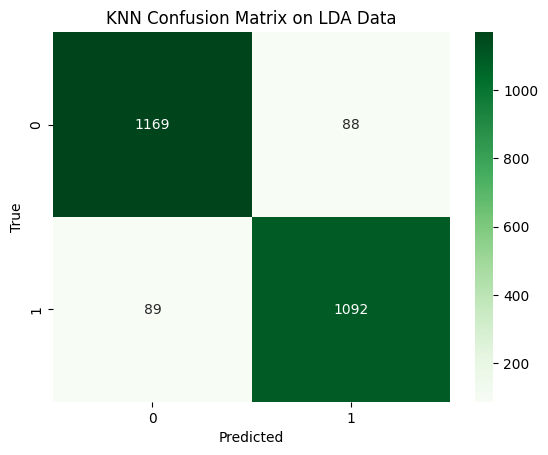

In [ ]:
# Initialize the KNN model
# knn = KNeighborsClassifier(n_neighbors=1)  # You can tune n_neighbors for better results

# Train the KNN model on the LDA-transformed data (optional)
knn_lda = KNeighborsClassifier(n_neighbors=1)
knn_lda.fit(X_train_lda, y_train)
# Predict on LDA-transformed test set
y_pred_lda = knn_lda.predict(X_test_lda)

# Calculate accuracy and print classification report
accuracy_lda = accuracy_score(y_test, y_pred_lda)
print("KNN Model Accuracy on LDA Data:", accuracy_lda)
print("KNN Classification Report on LDA Data:\n", classification_report(y_test, y_pred_lda))

# Confusion matrix
cm_lda = confusion_matrix(y_test, y_pred_lda)
sns.heatmap(cm_lda, annot=True, fmt="d", cmap="Greens")
plt.title("KNN Confusion Matrix on LDA Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Logistic Rigression

Number of unique classes: 2
Accuracy: 0.9495488105004102


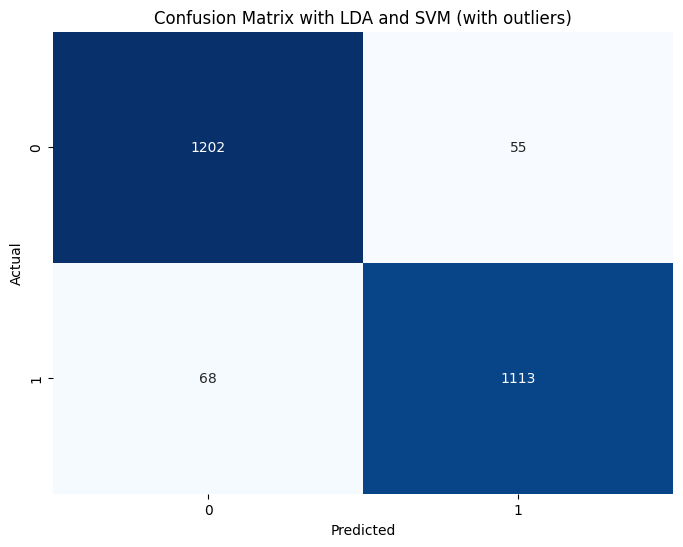

In [ ]:
# Check the number of unique classes in y_train
n_classes = len(np.unique(y_train))
print(f"Number of unique classes: {n_classes}")

# Adjust n_components based on the number of features and classes
n_components = min(n_classes - 1, X_train_scaled.shape[1])
# n_components should be at most (number of classes - 1) and less than or equal to the number of features

# Apply LDA
lda = LDA(n_components=n_components)
lr_train_lda = lda.fit_transform(X_train_scaled, y_train)
lr_test_lda = lda.transform(X_test_scaled)

# Train a classifier on the LDA-transformed training data
classifier = LogisticRegression()
classifier.fit(lr_train_lda, y_train)

# Make predictions on the LDA-transformed test data
y_lr_pred = classifier.predict(X_test_lda)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_lr_pred)
print("Accuracy:", accuracy_lr)

# Plot confusion matrix
conf_matrix = confusion_matrix(y_test, y_lr_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with LDA and SVM (with outliers)')
plt.show()

SVM

Accuracy with LDA and SVM (with outliers): 0.950369155045119


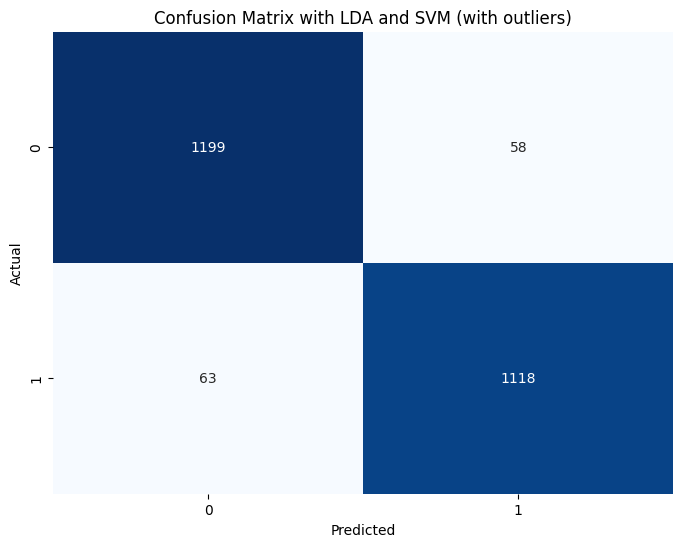

In [ ]:
# Train an SVM classifier on the LDA-transformed training data
svm = SVC(kernel='linear')
svm.fit(X_train_lda, y_train)

# Predictions and evaluation for SVM with outliers
y_pred = svm.predict(X_test_lda)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy with LDA and SVM (with outliers):", accuracy)

# Plot confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with LDA and SVM (with outliers)')
plt.show()


Decision Tree

Accuracy with LDA and Decision Tree (with outliers): 0.9273995077932732


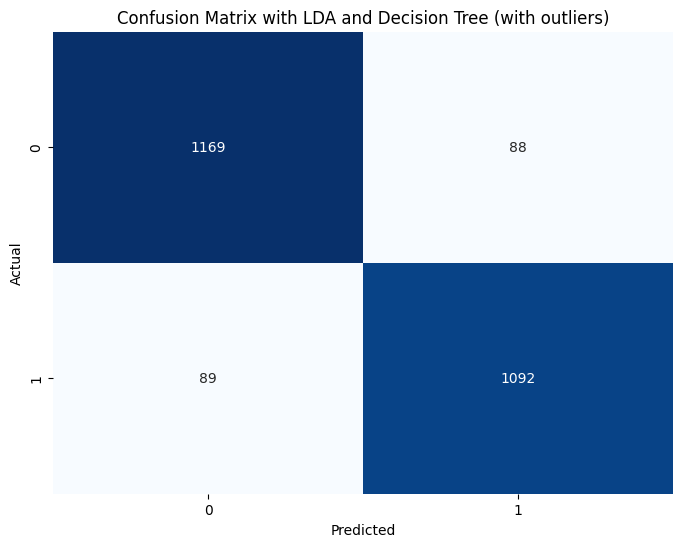

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Check and adjust lengths of the training data
X_train_lda_shape, y_train_shape = X_train_lda.shape[0], len(y_train)
if X_train_lda_shape != y_train_shape:
    y_train = y_train[:X_train_lda_shape]

# Check and adjust lengths of the test data
X_test_lda_shape, y_test_shape = X_test_lda.shape[0], len(y_test)
if X_test_lda_shape != y_test_shape:
    y_test = y_test[:X_test_lda_shape]

# Train a Decision Tree classifier on the LDA-transformed training data
tree = DecisionTreeClassifier()
tree.fit(X_train_lda, y_train)

# Make predictions on the LDA-transformed test data
y_pred = tree.predict(X_test_lda)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy with LDA and Decision Tree (with outliers):", accuracy)

# Plot confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with LDA and Decision Tree (with outliers)')
plt.show()

## with LDA without Outliers

KNN

Accuracy with LDA and KNN (clean data): 0.9935185185185185


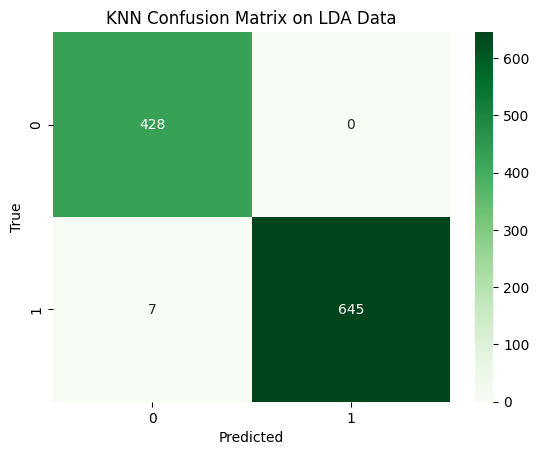

In [ ]:
# Apply LDA to your cleaned training data
lda = LDA(n_components=1) # Initialize LDA
knn_train_lda_clean = lda.fit_transform(X_train_clean, y_train_clean) # Fit and transform
knn_test_lda_clean = lda.transform(X_test_clean)

# Train a KNN classifier on the LDA-transformed training data
knn_clean = KNeighborsClassifier(n_neighbors=1)  # Adjust the number of neighbors as needed
knn.fit(knn_train_lda_clean, y_train_clean)

# Make predictions on the LDA-transformed test data
y_pred_clean_knn = knn.predict(knn_test_lda_clean)

# Calculate accuracy
accuracy_clean_knn = accuracy_score(y_test_clean, y_pred_clean_knn)
print("Accuracy with LDA and KNN (clean data):", accuracy_clean_knn)

# Confusion matrix
cm_knn = confusion_matrix(y_test_clean, y_pred_clean_knn)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Greens")
plt.title("KNN Confusion Matrix on LDA Data")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Logistic Regression

Accuracy: 0.9935185185185185


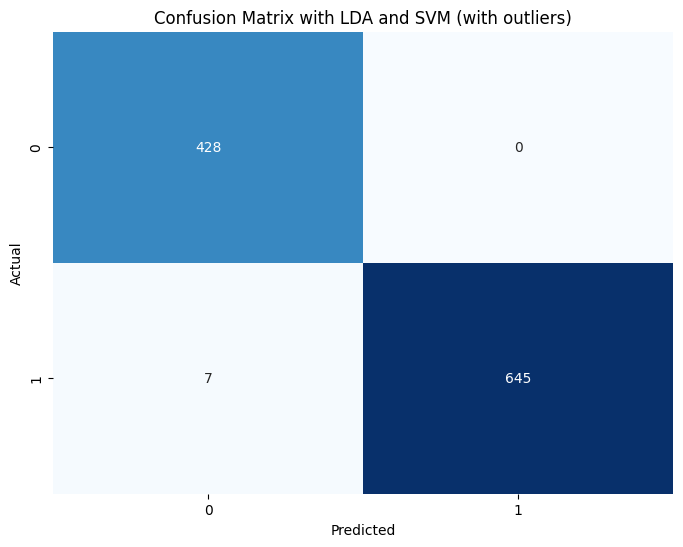

In [ ]:
# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# Number of unique classes
n_classes = len(np.unique(y_train_clean))

# Adjust n_components based on the number of features and classes
n_components = min(n_classes - 1, X_train_scaled.shape[1])

# Apply LDA
lda = LDA(n_components=n_components)
X_train_lda = lda.fit_transform(X_train_scaled, y_train_clean)
X_test_lda = lda.transform(X_test_scaled)

# Train a classifier on the LDA-transformed training data
classifier = LogisticRegression()
classifier.fit(X_train_lda, y_train_clean)

# Make predictions on the LDA-transformed test data
y_pred_clean_lr = classifier.predict(X_test_lda)

# Calculate accuracy
accuracy_clean = accuracy_score(y_test_clean, y_pred_clean_lr)
print("Accuracy:", accuracy_clean)

# Plot confusion matrix
conf_matrix_clean = confusion_matrix(y_test_clean, y_pred_clean_lr)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_clean, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with LDA and SVM (with outliers)')
plt.show()

SVM

Accuracy with LDA and SVM (without outliers): 1.0


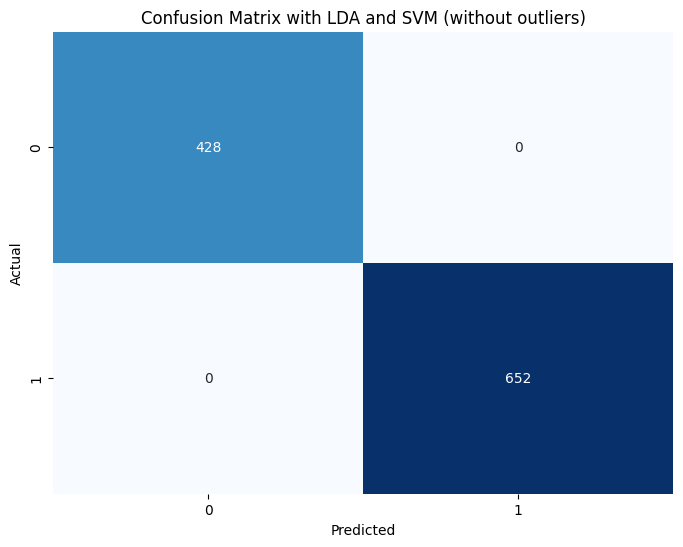

In [ ]:
# Train an SVM classifier on the LDA-transformed clean training data
svm_clean = SVC(kernel='linear')  # You can choose different kernels like 'rbf' if needed
svm_clean.fit(X_train_scaled_clean, y_train_clean)

# Make predictions on the LDA-transformed clean test data
y_pred_clean_svm = svm_clean.predict(X_test_scaled_clean)

# Calculate accuracy
accuracy_clean_svm = accuracy_score(y_test_clean, y_pred_clean_svm)
print("Accuracy with LDA and SVM (without outliers):", accuracy_clean_svm)

# Plot confusion matrix
conf_matrix_clean_svm = confusion_matrix(y_test_clean, y_pred_clean_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_clean_svm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with LDA and SVM (without outliers)')
plt.show()

Decision Tree

Accuracy with LDA and Decision Tree (without outliers): 1.0


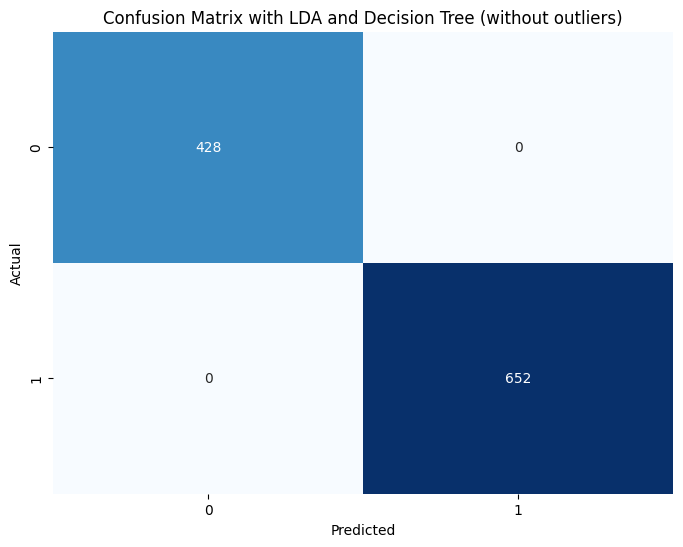

In [ ]:
# Train a Decision Tree classifier on the LDA-transformed clean training data
tree_clean = DecisionTreeClassifier()
tree_clean.fit(X_train_scaled_clean, y_train_clean)

# Make predictions on the LDA-transformed clean test data
y_pred_clean = tree_clean.predict(X_test_scaled_clean)

# Calculate accuracy
accuracy_clean = accuracy_score(y_test_clean, y_pred_clean)
print("Accuracy with LDA and Decision Tree (without outliers):", accuracy_clean)

# Plot confusion matrix
conf_matrix_clean = confusion_matrix(y_test_clean, y_pred_clean)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_clean, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with LDA and Decision Tree (without outliers)')
plt.show()